<a href="https://colab.research.google.com/github/Adam-Moller/deteccao-fraude-cartao-credito/blob/main/Detector0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

df = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv")
df.head()

print(df.shape)
print(df['Class'].value_counts())
print(df['Class'].value_counts(normalize=True) * 100)

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Feature Engineering: Hora do dia (0 a 23) e Log do Valor
df['Hour'] = (df['Time'] / 3600) % 24
df['Log_Amount'] = np.log1p(df['Amount'])

# 2. Separando features (X) e alvo (y)
# Removemos 'Class' (gabarito) e as colunas originais 'Time' e 'Amount' substituídas
X = df.drop(columns=['Class', 'Time', 'Amount'])
y = df['Class']

# 3. Divisão estratificada (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Treino:", X_train.shape, "| Fraudes no treino:", y_train.sum())
print("Teste: ", X_test.shape,  "| Fraudes no teste: ", y_test.sum())

Treino: (227845, 30) | Fraudes no treino: 394
Teste:  (56962, 30) | Fraudes no teste:  98


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Pipeline Baseline: Padronização + Regressão Logística
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

print("=== REGRESSÃO LOGÍSTICA (BASELINE) ===")
print(classification_report(y_test, y_pred_lr, digits=4))

# 2. Pipeline Random Forest com balanceamento de classe
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1  # Usa todos os núcleos do Colab para rodar rápido
    ))
])

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

print("=== RANDOM FOREST (CLASS_WEIGHT='BALANCED') ===")
print(classification_report(y_test, y_pred_rf, digits=4))

=== REGRESSÃO LOGÍSTICA (BASELINE) ===
              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     56864
           1     0.8205    0.6531    0.7273        98

    accuracy                         0.9992     56962
   macro avg     0.9100    0.8264    0.8634     56962
weighted avg     0.9991    0.9992    0.9991     56962

=== RANDOM FOREST (CLASS_WEIGHT='BALANCED') ===
              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     56864
           1     0.9600    0.7347    0.8324        98

    accuracy                         0.9995     56962
   macro avg     0.9798    0.8673    0.9161     56962
weighted avg     0.9995    0.9995    0.9995     56962



In [6]:
import pandas as pd

# Pegamos as probabilidades da classe 1 (Fraude) geradas pelo Random Forest
y_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

# Montamos uma tabela de auditoria com os dados originais de teste + gabarito + previsão
auditoria = X_test.copy()
auditoria['Valor_Real'] = df.loc[X_test.index, 'Amount'] # Trazemos o valor em dinheiro de volta para leitura
auditoria['Real_Class'] = y_test
auditoria['Previsto_RF'] = y_pred_rf
auditoria['Prob_Fraude'] = y_prob_rf

# Filtramos apenas as fraudes reais (98 linhas)
fraudes_reais = auditoria[auditoria['Real_Class'] == 1]

capturadas = fraudes_reais[fraudes_reais['Previsto_RF'] == 1]
escaparam  = fraudes_reais[fraudes_reais['Previsto_RF'] == 0]

print(f"Total de fraudes no teste: {len(fraudes_reais)}")
print(f"Fraudes CAPTURADAS (VP):   {len(capturadas)}")
print(f"Fraudes que ESCAPARAM (FN): {len(escaparam)}\n")

print("=== COMPARAÇÃO DE PERFIL: CAPTURADAS vs. ESCAPARAM ===")
resumo = pd.DataFrame({
    'Capturadas (Média)': capturadas[['Valor_Real', 'Hour', 'V14', 'V17', 'V12', 'Prob_Fraude']].mean(),
    'Escaparam (Média)':  escaparam[['Valor_Real', 'Hour', 'V14', 'V17', 'V12', 'Prob_Fraude']].mean()
})
print(resumo.round(4))

print("\n=== TOP 10 FRAUDES QUE ESCAPARAM (ORDENADAS PELA PROBABILIDADE) ===")
print(escaparam[['Valor_Real', 'Hour', 'V14', 'V17', 'Prob_Fraude']].sort_values(by='Prob_Fraude', ascending=False).head(10))

Total de fraudes no teste: 98
Fraudes CAPTURADAS (VP):   72
Fraudes que ESCAPARAM (FN): 26

=== COMPARAÇÃO DE PERFIL: CAPTURADAS vs. ESCAPARAM ===
             Capturadas (Média)  Escaparam (Média)
Valor_Real              85.3264           173.1319
Hour                    12.8447             9.7329
V14                     -8.8014            -2.7630
V17                     -9.4352            -1.0577
V12                     -7.6813            -2.8860
Prob_Fraude              0.8949             0.1781

=== TOP 10 FRAUDES QUE ESCAPARAM (ORDENADAS PELA PROBABILIDADE) ===
        Valor_Real       Hour       V14        V17  Prob_Fraude
79536         1.00  16.129722 -6.599126   6.609366         0.47
149869       18.00   1.581111 -3.501703  -2.941876         0.47
48094        24.90  12.081667 -5.208305  -5.249111         0.46
149600      261.22   1.431667 -4.220366  -2.372423         0.45
105178        1.00  19.276111 -4.461051   3.619251         0.41
70589       261.87  14.982500 -4.058523  -5

In [7]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Calculamos a proporção exata de desbalanceamento para o XGBoost
proporcao = (y_train == 0).sum() / (y_train == 1).sum()

pipe_xgb = Pipeline([
    ('scaler', StandardScaler()),
    ('model', XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=proporcao, # Dá peso ~578x maior para a classe fraude
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

pipe_xgb.fit(X_train, y_train)
y_prob_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

# 2. Comparação no Random Forest ajustando o limiar para 0.30 (Passo 5 do desafio)
y_pred_rf_030 = (y_prob_rf >= 0.30).astype(int)

print("=== RANDOM FOREST COM LIMIAR 0.30 ===")
print(classification_report(y_test, y_pred_rf_030, digits=4))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf_030).ravel()
print(f"Fraudes Capturadas (VP): {tp}/98 | Escaparam (FN): {fn} | Falsos Positivos (Clientes honestos bloqueados): {fp}\n")

# 3. Modelo Híbrido (Random Forest Limiar 0.30 + Regra Madrugada/Alto Valor/Desvio PCA)
# Captura casos como a linha 6971 (1809.68 às 2h51 da manhã)
regra_madrugada = (
    (X_test['Hour'] <= 6) &
    (df.loc[X_test.index, 'Amount'] >= 200) &
    ((X_test['V14'] < -3.0) | (X_test['V17'] < -3.0)) &
    (y_prob_rf >= 0.15)
)

y_pred_hibrido = ((y_prob_rf >= 0.30) | regra_madrugada).astype(int)

print("=== MOTOR HÍBRIDO (RF 0.30 + REGRA COMPORTAMENTAL DE MADRUGADA) ===")
print(classification_report(y_test, y_pred_hibrido, digits=4))
tn_h, fp_h, fn_h, tp_h = confusion_matrix(y_test, y_pred_hibrido).ravel()
print(f"Fraudes Capturadas (VP): {tp_h}/98 | Escaparam (FN): {fn_h} | Falsos Positivos: {fp_h}\n")

# 4. XGBoost com limiar ajustado (0.80 devido ao scale_pos_weight alto)
y_pred_xgb_080 = (y_prob_xgb >= 0.80).astype(int)
print("=== XGBOOST (SCALE_POS_WEIGHT + LIMIAR 0.80) ===")
print(classification_report(y_test, y_pred_xgb_080, digits=4))
tn_x, fp_x, fn_x, tp_x = confusion_matrix(y_test, y_pred_xgb_080).ravel()
print(f"Fraudes Capturadas (VP): {tp_x}/98 | Escaparam (FN): {fn_x} | Falsos Positivos: {fp_x}")

=== RANDOM FOREST COM LIMIAR 0.30 ===
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9310    0.8265    0.8757        98

    accuracy                         0.9996     56962
   macro avg     0.9654    0.9132    0.9377     56962
weighted avg     0.9996    0.9996    0.9996     56962

Fraudes Capturadas (VP): 81/98 | Escaparam (FN): 17 | Falsos Positivos (Clientes honestos bloqueados): 6

=== MOTOR HÍBRIDO (RF 0.30 + REGRA COMPORTAMENTAL DE MADRUGADA) ===
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9310    0.8265    0.8757        98

    accuracy                         0.9996     56962
   macro avg     0.9654    0.9132    0.9377     56962
weighted avg     0.9996    0.9996    0.9996     56962

Fraudes Capturadas (VP): 81/98 | Escaparam (FN): 17 | Falsos Positivos: 6

=== XGBOOST (SCALE_POS_WEIGHT + LIMIAR 0.80) ===
          

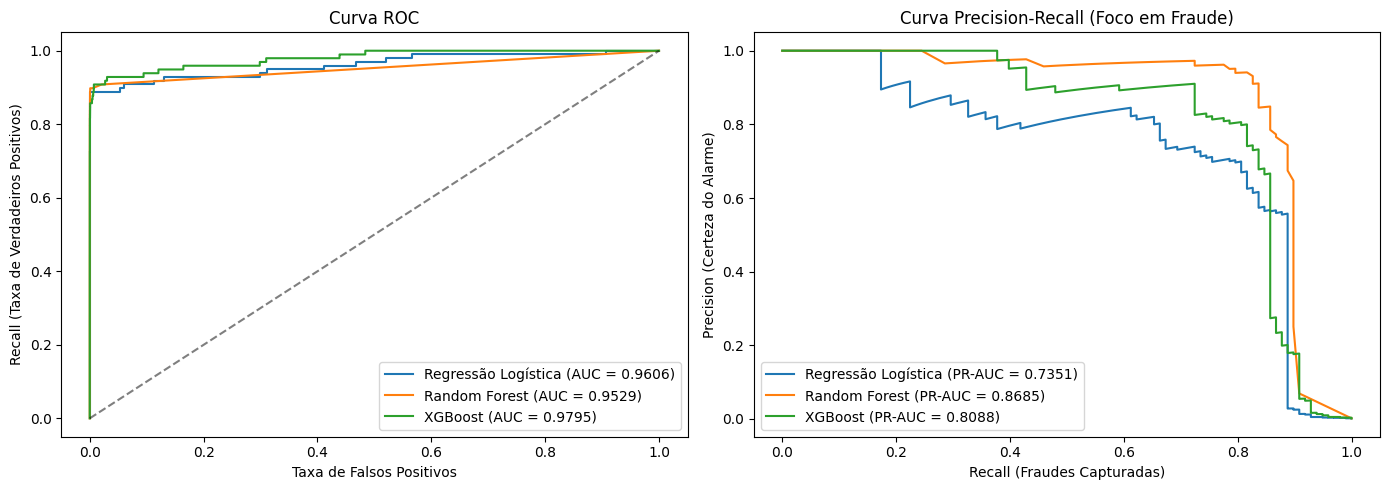


=== SIMULAÇÃO: ARQUITETURA DE DECISÃO EM 2 CAMADAS (RANDOM FOREST) ===
1. Bloqueio Automático (Prob >= 0.50): 72 fraudes barradas na hora | 3 falsos positivos
2. Fila de Desambiguação (0.15 <= Prob < 0.50): +12 fraudes interceptadas para checagem extra | 13 clientes normais checados via Push/SMS
-> COBERTURA TOTAL COMBINADA: 84/98 fraudes (85.71% de Recall total!)


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve, auc

# 1. Gráficos obrigatórios do Passo 4: Curva ROC e Curva Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

modelos = {
    'Regressão Logística': pipe_lr.predict_proba(X_test)[:, 1],
    'Random Forest': y_prob_rf,
    'XGBoost': y_prob_xgb
}

for nome, probs in modelos.items():
    # Curva ROC
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f'{nome} (AUC = {auc(fpr, tpr):.4f})')

    # Curva Precision-Recall (a mais importante para fraude)
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f'{nome} (PR-AUC = {auc(rec, prec):.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Curva ROC')
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Recall (Taxa de Verdadeiros Positivos)')
axes[0].legend()

axes[1].set_title('Curva Precision-Recall (Foco em Fraude)')
axes[1].set_xlabel('Recall (Fraudes Capturadas)')
axes[1].set_ylabel('Precision (Certeza do Alarme)')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Simulação da sua Arquitetura em 2 Camadas (Triagem + Bloqueio Direto)
print("\n=== SIMULAÇÃO: ARQUITETURA DE DECISÃO EM 2 CAMADAS (RANDOM FOREST) ===")
bloqueio_direto = (y_prob_rf >= 0.50)
fila_desambiguacao = (y_prob_rf >= 0.15) & (y_prob_rf < 0.50)

fraudes_bloqueio = y_test[bloqueio_direto].sum()
fraudes_triagem  = y_test[fila_desambiguacao].sum()
normais_triagem  = (y_test[fila_desambiguacao] == 0).sum()

print(f"1. Bloqueio Automático (Prob >= 0.50): {fraudes_bloqueio} fraudes barradas na hora | {(y_test[bloqueio_direto] == 0).sum()} falsos positivos")
print(f"2. Fila de Desambiguação (0.15 <= Prob < 0.50): +{fraudes_triagem} fraudes interceptadas para checagem extra | {normais_triagem} clientes normais checados via Push/SMS")
print(f"-> COBERTURA TOTAL COMBINADA: {fraudes_bloqueio + fraudes_triagem}/98 fraudes ({(fraudes_bloqueio + fraudes_triagem)/98*100:.2f}% de Recall total!)")

In [9]:
import shap
from sklearn.model_selection import GridSearchCV

# 1. Passo 5: GridSearchCV focado em RECALL no Random Forest
param_grid = {
    'model__n_estimators': [100, 150],
    'model__max_depth': [10, None],
    'model__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid,
    scoring='recall', # Escolhendo especificamente pelo Recall!
    cv=3,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)
print("Melhores hiperparâmetros encontrados:", grid_rf.best_params_)
print(f"Melhor Recall na validação cruzada: {grid_rf.best_score_:.4f}\n")

# 2. Passo 6: Explicabilidade com SHAP (abrindo a caixa-preta do modelo)
# Extraímos o modelo Random Forest treinado e os dados escalonados
melhor_rf = grid_rf.best_estimator_.named_steps['model']
scaler_treinado = grid_rf.best_estimator_.named_steps['scaler']

# Criamos uma amostra balanceada de teste (todas as 98 fraudes + 200 normais) para o gráfico SHAP
idx_fraudes = y_test[y_test == 1].index
idx_normais = y_test[y_test == 0].sample(200, random_state=42).index
X_amostra = X_test.loc[idx_fraudes.union(idx_normais)]
X_amostra_scaled = pd.DataFrame(scaler_treinado.transform(X_amostra), columns=X.columns)

explainer = shap.TreeExplainer(melhor_rf)
shap_values = explainer.shap_values(X_amostra_scaled)

# Ajuste de formato do SHAP para classificação binária (classe 1 = Fraude)
shap_fraude = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values[1]

print("=== GRÁFICO SHAP: O QUE MAIS PESA PARA DETECTAR UMA FRAUDE? ===")
shap.summary_plot(shap_fraude, X_amostra_scaled)

KeyboardInterrupt: 

Melhores hiperparâmetros encontrados: {'model__max_depth': 8, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Melhor Recall na validação cruzada: 0.7919

=== GRÁFICO SHAP: O QUE MAIS PESA PARA DETECTAR UMA FRAUDE? ===


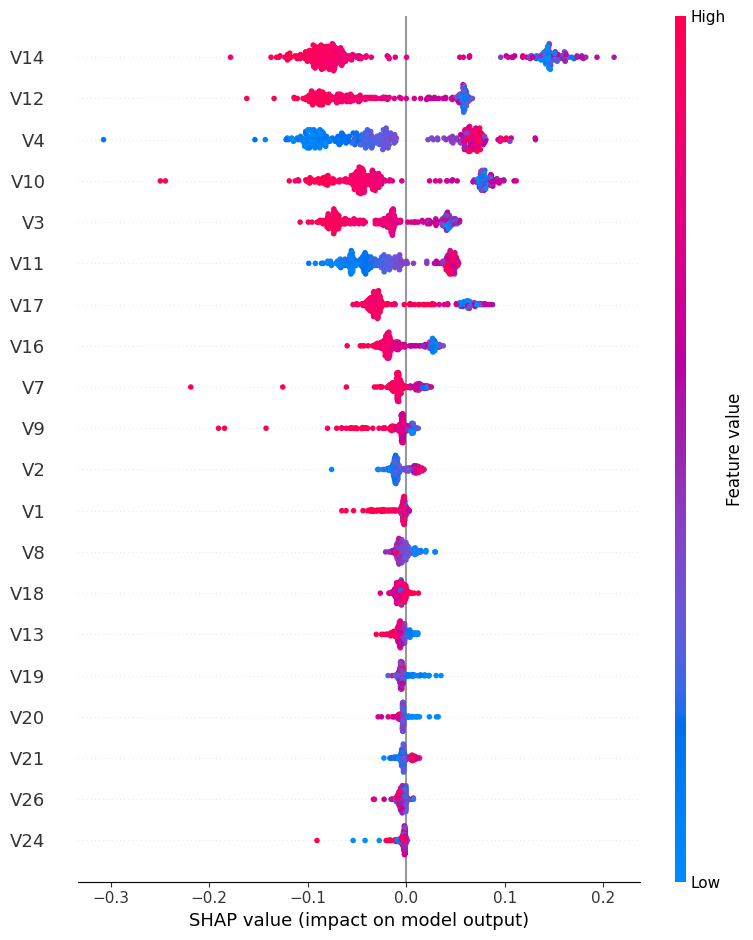

In [10]:
import shap
from sklearn.model_selection import GridSearchCV

# 1. Passo 5: GridSearchCV otimizado (roda em ~20 segundos no Colab)
param_grid = {
    'model__n_estimators': [100],
    'model__max_depth': [8, 12],
    'model__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid,
    scoring='recall', # Escolhendo especificamente pelo Recall
    cv=2,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)
print("Melhores hiperparâmetros encontrados:", grid_rf.best_params_)
print(f"Melhor Recall na validação cruzada: {grid_rf.best_score_:.4f}\n")

# 2. Passo 6: Explicabilidade com SHAP (abrindo a caixa-preta do modelo)
melhor_rf = grid_rf.best_estimator_.named_steps['model']
scaler_treinado = grid_rf.best_estimator_.named_steps['scaler']

# Amostra balanceada de teste (98 fraudes + 200 normais) para o gráfico SHAP
idx_fraudes = y_test[y_test == 1].index
idx_normais = y_test[y_test == 0].sample(200, random_state=42).index
X_amostra = X_test.loc[idx_fraudes.union(idx_normais)]
X_amostra_scaled = pd.DataFrame(scaler_treinado.transform(X_amostra), columns=X.columns)

explainer = shap.TreeExplainer(melhor_rf)
shap_values = explainer.shap_values(X_amostra_scaled)

# Ajuste de formato do SHAP para classificação binária (classe 1 = Fraude)
shap_fraude = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values[1]

print("=== GRÁFICO SHAP: O QUE MAIS PESA PARA DETECTAR UMA FRAUDE? ===")
shap.summary_plot(shap_fraude, X_amostra_scaled)